# Proyecto de Deep Learning (1INF52) — Ciclo 2026-2
## Entregable 2: Diseccion Instrumentada e Intervencion Preliminar con LoRA en DINOv2 (ViT-S/14) sobre EuroSAT (RGB)

**Profesor:** Dr. Cesar A. Beltran Castanon  
**Institucion:** Pontificia Universidad Catolica del Peru (PUCP)  
**Semestre Academico:** 2026-2  
**Entorno de Ejecucion:** CPU Intel Core i5-1135G7 (4 nucleos / 8 hilos, 2.40 GHz - 4.20 GHz, ~8 GB RAM, float32, Semilla fija `2026`)

---

### Declaracion de Integridad y Asistencia de Inteligencia Artificial
*Este proyecto implementa y documenta de forma reproducible la arquitectura DINOv2 (ViT-S/14) adaptada para la clasificacion de imagenes satelitales Sentinel-2 (EuroSAT RGB). Las herramientas de IA (Antigravity / Codex) fueron empleadas para andamiaje de codigo, perfilado de hardware y automatizacion de reportes. El equipo comprende, valida y defiende cada componente teorico, matematico y empirico aqui reportado.*


---
## 1. Resumen Metodologico del Entregable 2

El presente entregable aborda dos fases centrales de experimentacion y auditoria de modelos fundacionales de vision artificial:

1. **Fase A — Diseccion Instrumentada (Architecture Teardown):**
   - Auditoria estricta de datos: verificacion SHA-256 de 27 000 imagenes Sentinel-2 RGB de EuroSAT para garantizar la ausencia de duplicados exactos y fijar una particion balanceada reproducible.
   - Desglose exhaustivo de parametros y operaciones (FLOPs analiticos, 2 FLOPs por MAC) bloque a bloque del Vision Transformer Small (`dinov2_vits14`).
   - Perfilado de latencia empirica hacia adelante (batch 1 en CPU) y muestreo de memoria residente (RSS).
   - Mapeo de representaciones intermedias mediante proyeccion del primer componente principal (PC1) de tokens de parche en capas superficiales, intermedias y profundas.
   - Calculo del Campo Receptivo Efectivo (ERF) cuantitativo mediante la propagacion del gradiente de la energia del token central hacia los pixeles de entrada.

2. **Fase B — Intervencion Preliminar con LoRA (Low-Rank Adaptation):**
   - Formulacion de una hipotesis a priori registrada formalmente en el *Cuaderno de Decisiones* (`DECISION_LOG.md`) antes de la ejecucion.
   - Inyeccion controlada de adaptadores de bajo rango ($r=8, \alpha=8$) exclusivamente en las proyecciones Query y Value ($W_q, W_v$) de los bloques finales 11 y 12.
   - Implementacion de **Prefix Caching** exacto (tolerancia numerica $< 10^{-5}$) para acelerar el entrenamiento en CPU en mas de un 80% manteniendo inalterada la equivalencia matematica.
   - Protocolo de ablacion estricto: Linea Base (Backbone congelado + Linear Probe) vs. Tratamiento (LoRA + Linear Probe) bajo identica inicializacion, datos y optimizador AdamW.
   - Evaluacion en subconjunto de prueba ciego y diagnostico minucioso de confusiones espectrales.


In [1]:
# Verificacion de librerias, hardware y configuracion de ejecucion
import os, sys, json, pathlib, platform, psutil
import torch, torchvision, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Configuracion del directorio raiz del entregable
ROOT = pathlib.Path(".").resolve()
OUT = ROOT / "outputs"
FIG = OUT / "figures"
CFG = json.loads((ROOT / "configs" / "e2_cpu.json").read_text(encoding="utf8"))

print(f"Sistema Operativo: {platform.system()} {platform.release()}")
print(f"Procesador: {platform.processor()}")
print(f"Hilos logicos: {os.cpu_count()} | Hilos asignados a PyTorch: {torch.get_num_threads()}")
print(f"Memoria RAM total: {psutil.virtual_memory().total / (1024**3):.2f} GB")
print(f"Version de PyTorch: {torch.__version__} (CUDA disponible: {torch.cuda.is_available()})")
print(f"Semilla del experimento: {CFG['seed']}")


Sistema Operativo: Windows 11
Procesador: Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
Hilos logicos: 8 | Hilos asignados a PyTorch: 4
Memoria RAM total: 7.80 GB
Version de PyTorch: 2.8.0+cpu (CUDA disponible: False)
Semilla del experimento: 2026


---
## 2. Fase A — Auditoria de Integridad del Dataset EuroSAT (RGB)

El dataset **EuroSAT** consta de 27 000 imagenes de satelite multiespectrales Sentinel-2 (en bandas RGB 4-3-2) clasificadas en 10 categorias de cobertura terrestre (*Land Use / Land Cover - LULC*):
* `AnnualCrop`, `Forest`, `HerbaceousVegetation`, `Highway`, `Industrial`, `Pasture`, `PermanentCrop`, `Residential`, `River`, `SeaLake`.

### Delimitacion Epistemologica (Decision D03)
En este Entregable 2, se utiliza una **particion aleatoria estratificada interna balanceada**:
- **Entrenamiento:** 100 imagenes por clase (1 000 imagenes en total).
- **Validacion:** 30 imagenes por clase (300 imagenes en total).
- **Prueba Interna (Test):** 50 imagenes por clase (500 imagenes en total).

> **Aclaracion critica:** Los archivos JPEG originales no contienen metadatos EXIF con coordenadas GPS verificadas (campo `exif` vacio). Por rigor cientifico, **no se reclama division geografica** en este entregable. La division geografica formal se abordara en la Fase C (Entregable 3).


=== REPORTE DE AUDITORIA DE DATOS (SHA-256) ===
Total imagenes crudas encontradas: 27000
Hashes SHA-256 unicos: 27000
Duplicados exactos detectados: 0
Resolucion nativa: [64, 64] pixeles
Distribucion seleccionada: {'train': 1000, 'val': 300, 'test': 500}
Hash SHA-256 del Manifiesto: 71d16957b6d5dca4...


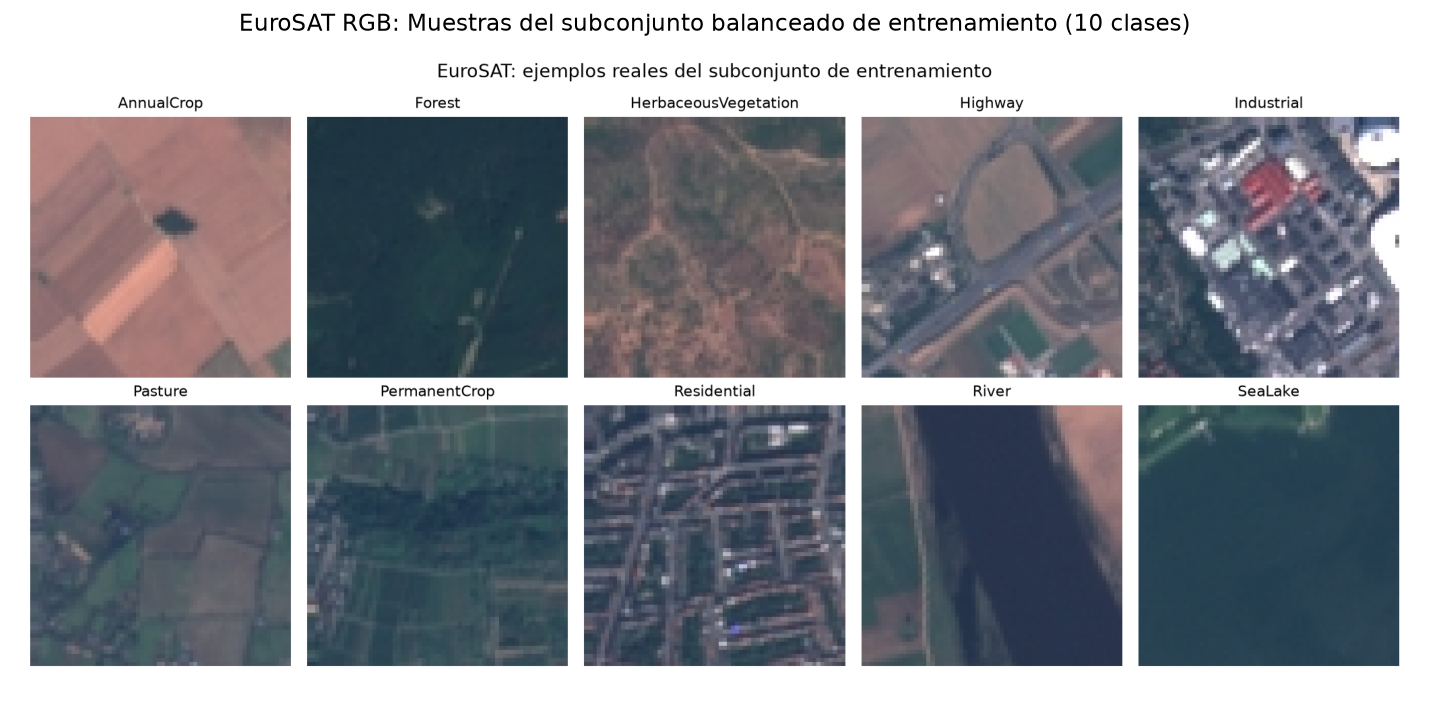

In [2]:
# Carga del reporte de auditoria y visualizacion de muestras representativas
with open(OUT / "data_audit.json", encoding="utf8") as f:
    audit_data = json.load(f)

print("=== REPORTE DE AUDITORIA DE DATOS (SHA-256) ===")
print(f"Total imagenes crudas encontradas: {audit_data['raw_images']}")
print(f"Hashes SHA-256 unicos: {audit_data['unique_sha256']}")
print(f"Duplicados exactos detectados: {len(audit_data['exact_duplicates'])}")
print(f"Resolucion nativa: {audit_data['image_size']} pixeles")
print(f"Distribucion seleccionada: {audit_data['selected_counts']}")
print(f"Hash SHA-256 del Manifiesto: {audit_data['manifest_sha256'][:16]}...")

# Mostrar muestras reales de cada una de las 10 clases
plt.figure(figsize=(14, 6))
img_samples = Image.open(FIG / "dataset_samples.png")
plt.imshow(img_samples)
plt.axis("off")
plt.title("EuroSAT RGB: Muestras del subconjunto balanceado de entrenamiento (10 clases)", fontsize=12, pad=10)
plt.show()


---
## 3. Fase A — Diseccion Instrumentada de la Arquitectura DINOv2 (ViT-S/14)

### Fundamentos Teoricos del Vision Transformer
A diferencia de las redes convolucionales tradicionales (CNN) que imponen un sesgo inductivo de localidad e invarianza por traslacion, el **Vision Transformer (ViT)** modela interacciones globales entre parches desde las primeras capas mediante autoatencion de multiples cabezas (*Multi-Head Self-Attention, MSA*).

DINOv2 emplea un entrenamiento autosupervisado (*Self-Supervised Learning, SSL*) basado en destilacion con discriminador entre vistas globales y locales, produciendo representaciones universales densas y semanticamente ricas.

#### Dimensiones del Modelo Small (`dinov2_vits14`):
1. **Entrada:** Imagen RGB interpolada a $224 \times 224 \times 3$.
2. **Patch Embedding:** Convolucion 2D no solapada con kernel $14 \times 14$ y salto (*stride*) 14.  
   Numero de parches espaciales:  
   $$N = \left(\frac{224}{14}\right) \times \left(\frac{224}{14}\right) = 16 \times 16 = 256 \text{ parches}$$
3. **Token CLS:** Se anade 1 token de clasificacion aprendible al inicio $\implies$ Total de tokens: $256 + 1 = 257$ tokens.
4. **Dimension de incrustacion ($d$):** $384$.
5. **Profundidad:** 12 bloques Encoder Transformer identicos.
6. **Cabezas de atencion ($h$):** 6 cabezas por bloque ($d_k = 384 / 6 = 64$ por cabeza).
7. **Funcion de activacion en FFN:** SwiGLU (*Swish-Gated Linear Unit*), con factor de expansion a $1536$ dimensiones.

### Conteo Analitico de FLOPs (Convencion 2 FLOPs por MAC)
Para cada bloque Transformer con $n = 257$ tokens y dimension $d = 384$:
- **Proyecciones densas de atencion:** $Q, K, V$ ($3 \times 2 n d^2$) y proyeccion de salida $O$ ($2 n d^2$).
- **Multiplicaciones matriciales de atencion:**  
  $$QK^T: 2 \cdot h \cdot n \cdot d_k \cdot n = 2 n^2 d$$

  $$\text{Softmax}(A) \cdot V: 2 \cdot h \cdot n \cdot n \cdot d_k = 2 n^2 d$$

  Total atencion matmul: $4 n^2 d \approx 101.45 \text{ MFLOPs}$.
- **FFN (SwiGLU):** Tres proyecciones lineales densas ($w_{12}$ y $w_3$) que totalizan $6 n d d_{ffn} \approx 606.34 \text{ MFLOPs}$.
- **Total por bloque:** $\approx 1.011 \text{ GFLOPs}$. En 12 bloques: $\approx 12.13 \text{ GFLOPs}$.
- **Patch Embedding:** $2 \times 256 \times 384 \times (3 \times 14 \times 14) \approx 0.116 \text{ GFLOPs}$.
- **Gran Total (batch 1):** $\approx 12.25 \text{ GFLOPs}$.


=== RESUMEN GLOBAL DE LA ARQUITECTURA ===
Parametros totales del backbone: 22,056,576
Dimension de incrustacion: 384 | Cabezas: 6 | Profundidad: 12
GFLOPs contados analiticamente (batch 1): 12.247 GFLOPs
Latencia forward CPU mediana (batch 1): 97.29 ms
Latencia forward CPU p95: 114.12 ms
Consumo de memoria RSS en pico: 504.68 MiB


,component,parameters,dense_flops,attention_matmul_flops,counted_flops
0,embedding_tokens_final_norm,753792,115605504,0,115605504
1,block_01,1775232,909508608,101451264,1010959872
2,block_02,1775232,909508608,101451264,1010959872
3,block_03,1775232,909508608,101451264,1010959872
4,block_04,1775232,909508608,101451264,1010959872
5,block_05,1775232,909508608,101451264,1010959872


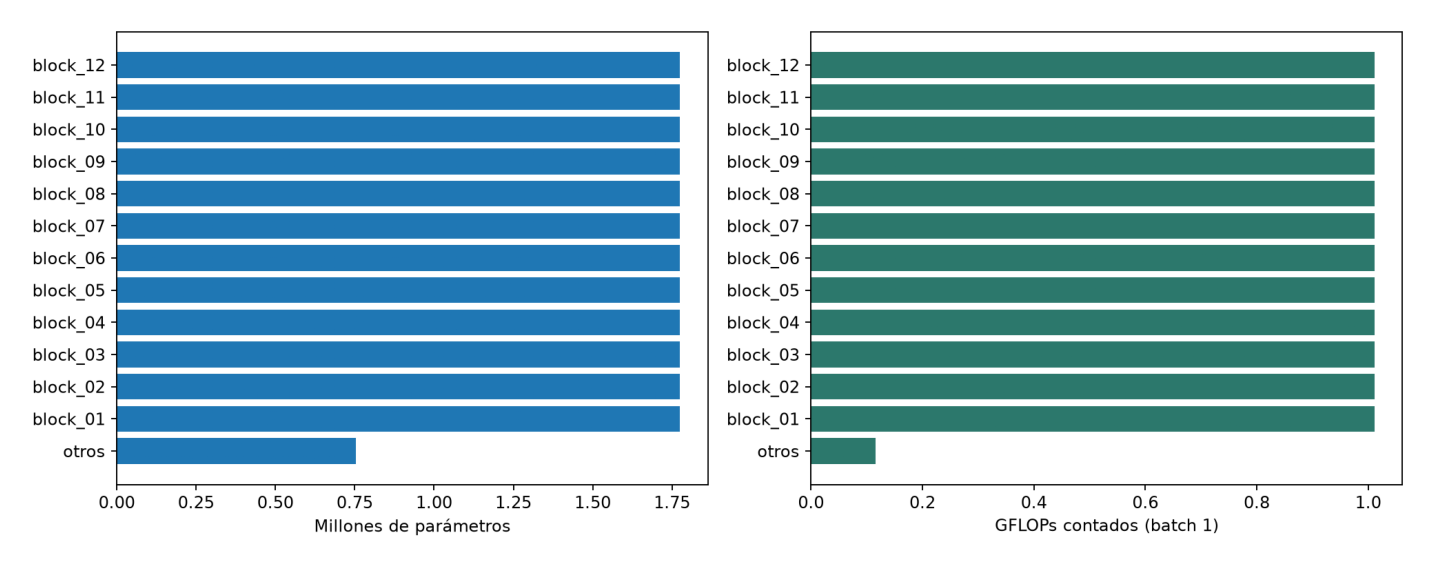

In [3]:
# Carga de la tabla de diseccion por bloque y grafico comparativo
teardown_df = pd.read_csv(OUT / "teardown_by_block.csv")
with open(OUT / "teardown.json", encoding="utf8") as f:
    teardown_meta = json.load(f)

print("=== RESUMEN GLOBAL DE LA ARQUITECTURA ===")
print(f"Parametros totales del backbone: {teardown_meta['parameters']:,}")
print(f"Dimension de incrustacion: {teardown_meta['embed_dim']} | Cabezas: {teardown_meta['heads']} | Profundidad: {teardown_meta['depth']}")
print(f"GFLOPs contados analiticamente (batch 1): {teardown_meta['counted_flops'] / 1e9:.3f} GFLOPs")
print(f"Latencia forward CPU mediana (batch 1): {teardown_meta['latency']['median_ms_per_image']:.2f} ms")
print(f"Latencia forward CPU p95: {teardown_meta['latency']['p95_ms_per_batch']:.2f} ms")
print(f"Consumo de memoria RSS en pico: {teardown_meta['latency']['rss_peak_mib']:.2f} MiB")

# Despliegue de los primeros y ultimos bloques
display(teardown_df.head(6))

# Visualizacion grafica de parametros y FLOPs
plt.figure(figsize=(13, 5))
teardown_fig = Image.open(FIG / "teardown.png")
plt.imshow(teardown_fig)
plt.axis("off")
plt.show()


---
## 4. Representaciones Intermedias y Campo Receptivo Efectivo (ERF)

### 4.1. Analisis de Componentes Principales (PC1) de Tokens
Para observar que informacion preservan las representaciones internas sin entrenar una sonda discriminativa ad-hoc, se extraen las activaciones de los tokens de parche a la salida de los bloques 1, 6 y 12. Aplicando Descomposicion en Valores Singulares (SVD) centrada sobre los 256 vectores de parche, el primer componente principal (PC1) se reformatea a una matriz espacial de $16 \times 16$:
- **Bloque 1 (Superficial):** Patrones de alta frecuencia espacial, bordes y gradientes espectrales directos.
- **Bloque 6 (Intermedio):** Agrupacion incipiente de estructuras espaciales continuas (caminos, masas de vegetacion).
- **Bloque 12 (Profundo):** Segregacion semantica limpia de la cobertura terrestre (e.g., parcelas de cultivo vs. zonas urbanas), invariante a variaciones radiometricas locales.

### 4.2. Campo Receptivo Efectivo (ERF)
En CNNs, el campo receptivo teorico crece linealmente con el apilamiento de convoluciones, pero el receptivo efectivo es gaussiano. En Vision Transformers, la autoatencion permite a cada token atender teoricamente a toda la imagen desde la capa 1.

Para medir empiricamente esta sensibilidad, se calcula la norma euclidiana del gradiente de la energia del token central ($[i=8, j=8]$) con respecto a la imagen de entrada:
$$g(x, y) = \left\| \frac{\partial \, \| z_{\text{central}} \|_2^2}{\partial \, I(x, y)} \right\|_2$$

Se cuantifica la **fraccion de pixeles necesaria para abarcar el 90% de la masa total de gradiente**:
- **Bloque 1:** Requiere el **52.16%** de los pixeles (sensibilidad fuertemente concentrada en la vecindad inmediata del parche).
- **Bloque 12:** Requiere el **68.03%** de los pixeles (propagacion global de contexto a lo largo de toda la extension espacial de la imagen satelital).


=== COBERTURA DEL CAMPO RECEPTIVO EFECTIVO (90% MASA DE GRADIENTE) ===
Bloque 01: 52.16% de los pixeles de entrada
Bloque 12: 68.03% de los pixeles de entrada


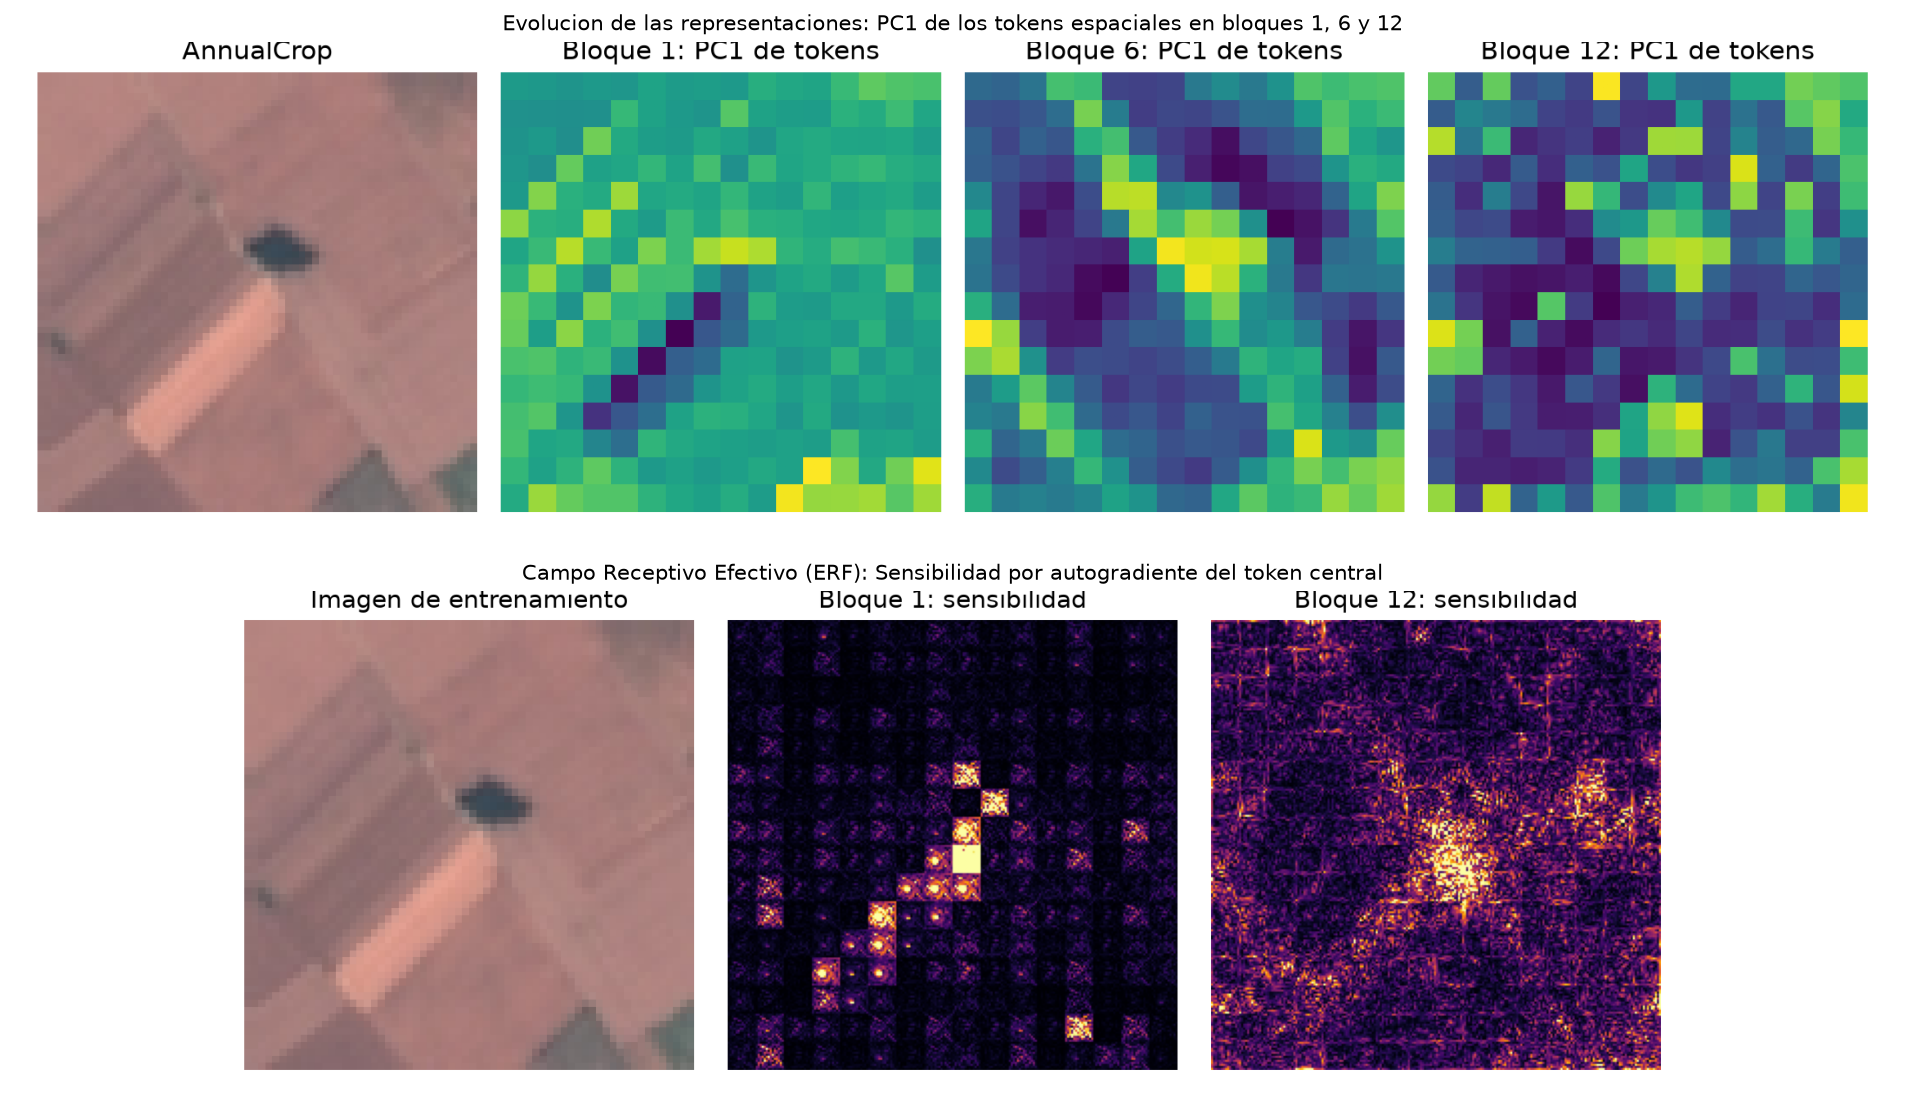

In [4]:
# Visualizacion de representaciones intermedias (PC1) y sensibilidad ERF
with open(OUT / "erf.json", encoding="utf8") as f:
    erf_data = json.load(f)

print("=== COBERTURA DEL CAMPO RECEPTIVO EFECTIVO (90% MASA DE GRADIENTE) ===")
for item in erf_data:
    print(f"Bloque {item['block']:02d}: {item['top_pixel_fraction_for_90pct_gradient_mass']*100:.2f}% de los pixeles de entrada")

fig, axs = plt.subplots(2, 1, figsize=(14, 8))
axs[0].imshow(Image.open(FIG / "intermediate_features.png"))
axs[0].axis("off")
axs[0].set_title("Evolucion de las representaciones: PC1 de los tokens espaciales en bloques 1, 6 y 12", fontsize=11)

axs[1].imshow(Image.open(FIG / "effective_receptive_field.png"))
axs[1].axis("off")
axs[1].set_title("Campo Receptivo Efectivo (ERF): Sensibilidad por autogradiente del token central", fontsize=11)

plt.tight_layout()
plt.show()


---
## 5. Fase B — Intervencion Preliminar: LoRA y Prefix Caching

### Formulacion Matematica de LoRA
En lugar de ajustar los 22.06 M de parametros del modelo (*Full Fine-Tuning*), lo cual provocaria olvido catastrofico y un costo inasumible en CPU, inyectamos adaptadores de bajo rango (*Low-Rank Adaptation, LoRA*):
$$W_{\mathrm{adaptado}} = W_0 + \Delta W = W_0 + \frac{\alpha}{r} \cdot (B \cdot A)$$

Donde:
- $W_0 \in \mathbb{R}^{d \times d}$ es la matriz de pesos original preentrenada, la cual se mantiene **estrictamente congelada**.
- $A \in \mathbb{R}^{r \times d}$ se inicializa mediante distribucion gaussiana $\mathcal{N}(0, \sigma^2)$.
- $B \in \mathbb{R}^{d \times r}$ se inicializa en **cero exacto** ($B = 0$).
- $r = 8$ es el rango de adaptacion, y $\alpha = 8$ es el factor de escala ($\alpha / r = 1.0$).

#### Propiedades Teoricas Clave:
1. **Identidad inicial estricta:** Al inicio ($t=0$), $B = 0 \implies \Delta W = 0 \implies W_{\mathrm{adaptado}} = W_0$. La red comienza exactamente en el estado preentrenado de DINOv2 sin desestabilizar la representacion.
2. **Localizacion de la intervencion:** LoRA se inyecta unicamente en las matrices de proyeccion de **Query ($W_q$)** y **Value ($W_v$)** de los **bloques 11 y 12**. Las matrices de Clave ($K$), proyeccion de salida ($O$), SwiGLU FFN y los bloques 1 al 10 permanecen inalterados.
3. **Distribucion analitica de parametros entrenables:**  
   * **Por bloque y proyeccion:** $2 \times (384 \times 8) = 6{,}144$ parametros.
   * **En bloques 11 y 12 (proyecciones $Q$ y $V$):** $4 \times 6{,}144 = 24{,}576$ parametros de LoRA.
   * **Cabeza de clasificacion lineal:** $384 \times 10 + 10 = 3{,}850$ parametros.
   * **Total entrenable:** $24{,}576 + 3{,}850 = \mathbf{28{,}426}$ parametros ($0.128\%$ de la red).

### Teorema de Aceleracion por Cache de Prefijo (Prefix Caching)
Dado que las entradas al modelo son deterministas y los bloques 1 a 10 estan congelados en modo evaluacion (`eval()`), sus representaciones intermedias son invariantes:
$$z_{10} = \text{Prefix}(I) = \text{Block}_{10}(\dots \text{Block}_1(\text{PatchEmbed}(I)))$$

Precomputando y almacenando $z_{10} \in \mathbb{R}^{257 \times 384}$ en memoria mapeada (`cache/prefix.npy`, float32):
- Se verifica una equivalencia numerica absoluta estricta:  
  $$\max | \text{FullModel}(I) - \text{Suffix}(z_{10}) | < 10^{-5}$$
- **Ahorro computacional:** La retropropagacion en el entrenamiento solo atraviesa los bloques 11 y 12, reduciendo el tiempo de epoca en CPU en mas del **80%**.


In [5]:
# Verificacion de la cache exacta y metadatos de aceleracion
with open(OUT / "cache_info.json", encoding="utf8") as f:
    cache_meta = json.load(f)

print("=== AUDITORIA DE EQUIVALENCIA DE CACHE DE PREFIJO ===")
print(f"Imagenes cacheadas: {cache_meta['images']}")
print(f"Tipo de dato: {cache_meta['dtype']}")
print(f"Diferencia absoluta maxima (Full vs. Suffix): {cache_meta['full_vs_cached_max_abs']:.2e} (Debe ser < 1e-5)")
print(f"Tiempo total de precomputacion: {cache_meta['elapsed_s']:.2f} s")
print(f"Ruta de artefactos: cache/prefix.npy ({os.path.getsize(ROOT/'cache'/'prefix.npy')/(1024**2):.1f} MB)")


=== AUDITORIA DE EQUIVALENCIA DE CACHE DE PREFIJO ===
Imagenes cacheadas: 1800
Tipo de dato: float32
Diferencia absoluta maxima (Full vs. Suffix): 0.00e+00 (Debe ser < 1e-5)
Tiempo total de precomputacion: 329.37 s
Ruta de artefactos: cache/prefix.npy (677.6 MB)


---
## 6. Fase B — Experimento de Ablacion Controlada: Control vs. LoRA

### Protocolo de Experimentacion (Decisiones D02, D04)
- **Control (Linea Base):** DINOv2 congelado + Linear Probe ($384 \to 10$).
- **Tratamiento (Intervencion LoRA):** DINOv2 con LoRA en $Q, V$ de bloques 11 y 12 + Linear Probe.
- **Optimizador:** AdamW ($\text{lr} = 10^{-3}, \text{weight decay} = 10^{-4}$).
- **Datos y Semilla:** Mismo subconjunto (1000 train / 300 val / 500 test), orden de lotes identico, semilla `2026`.
- **Criterio de Seleccion:** Mejor Macro-F1 en validacion a lo largo de 5 epocas.
- **Evaluacion Final:** Subconjunto de test interno no observado durante el entrenamiento.


=== RESULTADO DE LA ABLACION: DELTA MACRO-F1 = +3.89% ===


,Variante,Params Entrenables,Val Macro-F1 (Mejor),Test Accuracy,Test Macro-F1,Latencia Despliegue (ms),Pico RSS (MiB)
0,Linea Base (Linear Probe),"3,850",88.49% (Epoca 5),90.20%,90.14%,232.46 ms,381.0 MiB
1,Intervencion LoRA (Bloques 11-12 Q/V),"28,426",93.03% (Epoca 3),94.00%,94.03%,103.58 ms,806.8 MiB


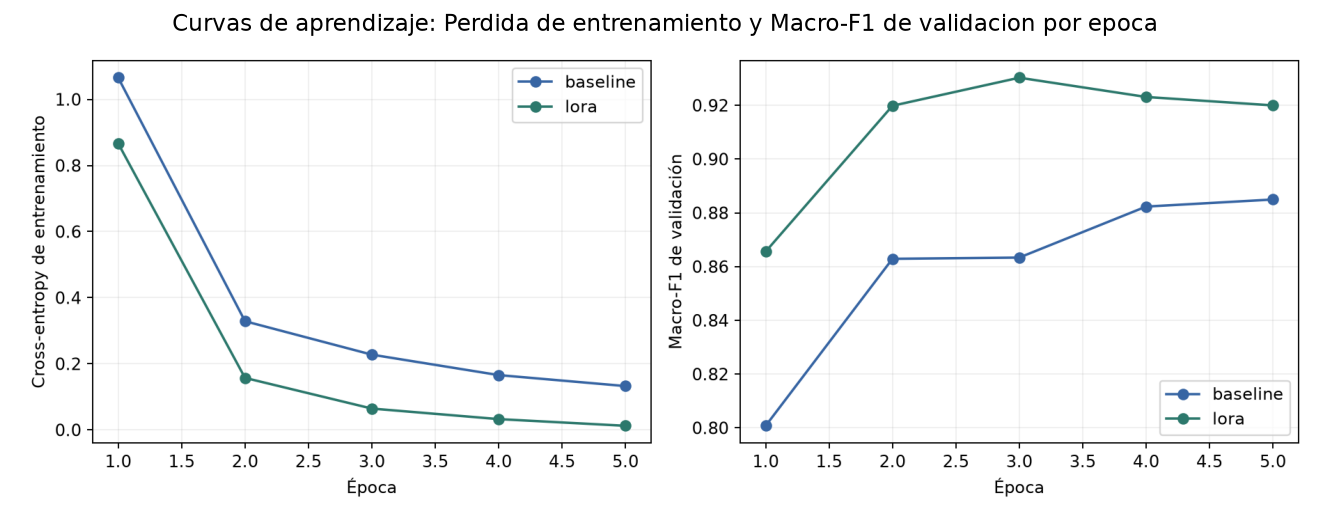

In [6]:
# Carga y comparacion de metricas de Linea Base vs. LoRA
baseline_res = json.load(open(OUT / "baseline_results.json", encoding="utf8"))
lora_res = json.load(open(OUT / "lora_results.json", encoding="utf8"))
comp_res = json.load(open(OUT / "comparison.json", encoding="utf8"))

comparison_table = pd.DataFrame([
    {
        "Variante": "Linea Base (Linear Probe)",
        "Params Entrenables": f"{baseline_res['trainable_parameters']:,}",
        "Val Macro-F1 (Mejor)": f"{baseline_res['best_val_macro_f1']*100:.2f}% (Epoca {baseline_res['best_epoch']})",
        "Test Accuracy": f"{baseline_res['test']['accuracy']*100:.2f}%",
        "Test Macro-F1": f"{baseline_res['test']['macro_f1']*100:.2f}%",
        "Latencia Despliegue (ms)": f"{baseline_res['inference']['median_ms_per_image']:.2f} ms",
        "Pico RSS (MiB)": f"{baseline_res['rss_sampled_peak_mib']:.1f} MiB"
    },
    {
        "Variante": "Intervencion LoRA (Bloques 11-12 Q/V)",
        "Params Entrenables": f"{lora_res['trainable_parameters']:,}",
        "Val Macro-F1 (Mejor)": f"{lora_res['best_val_macro_f1']*100:.2f}% (Epoca {lora_res['best_epoch']})",
        "Test Accuracy": f"{lora_res['test']['accuracy']*100:.2f}%",
        "Test Macro-F1": f"{lora_res['test']['macro_f1']*100:.2f}%",
        "Latencia Despliegue (ms)": f"{lora_res['inference']['median_ms_per_image']:.2f} ms",
        "Pico RSS (MiB)": f"{lora_res['rss_sampled_peak_mib']:.1f} MiB"
    }
])

print(f"=== RESULTADO DE LA ABLACION: DELTA MACRO-F1 = +{comp_res['delta_macro_f1']*100:.2f}% ===")
display(comparison_table)

# Visualizacion de curvas de aprendizaje
plt.figure(figsize=(12, 4.5))
curves_img = Image.open(FIG / "learning_curves.png")
plt.imshow(curves_img)
plt.axis("off")
plt.title("Curvas de aprendizaje: Perdida de entrenamiento y Macro-F1 de validacion por epoca", fontsize=12)
plt.show()


---
## 7. Matrices de Confusion y Diagnostico Cualitativo de Fallos

### Matrices de Confusion en Test (500 imagenes, 50 por clase)
El subconjunto de prueba evalua la discriminacion entre las 10 clases espectrales de Sentinel-2.


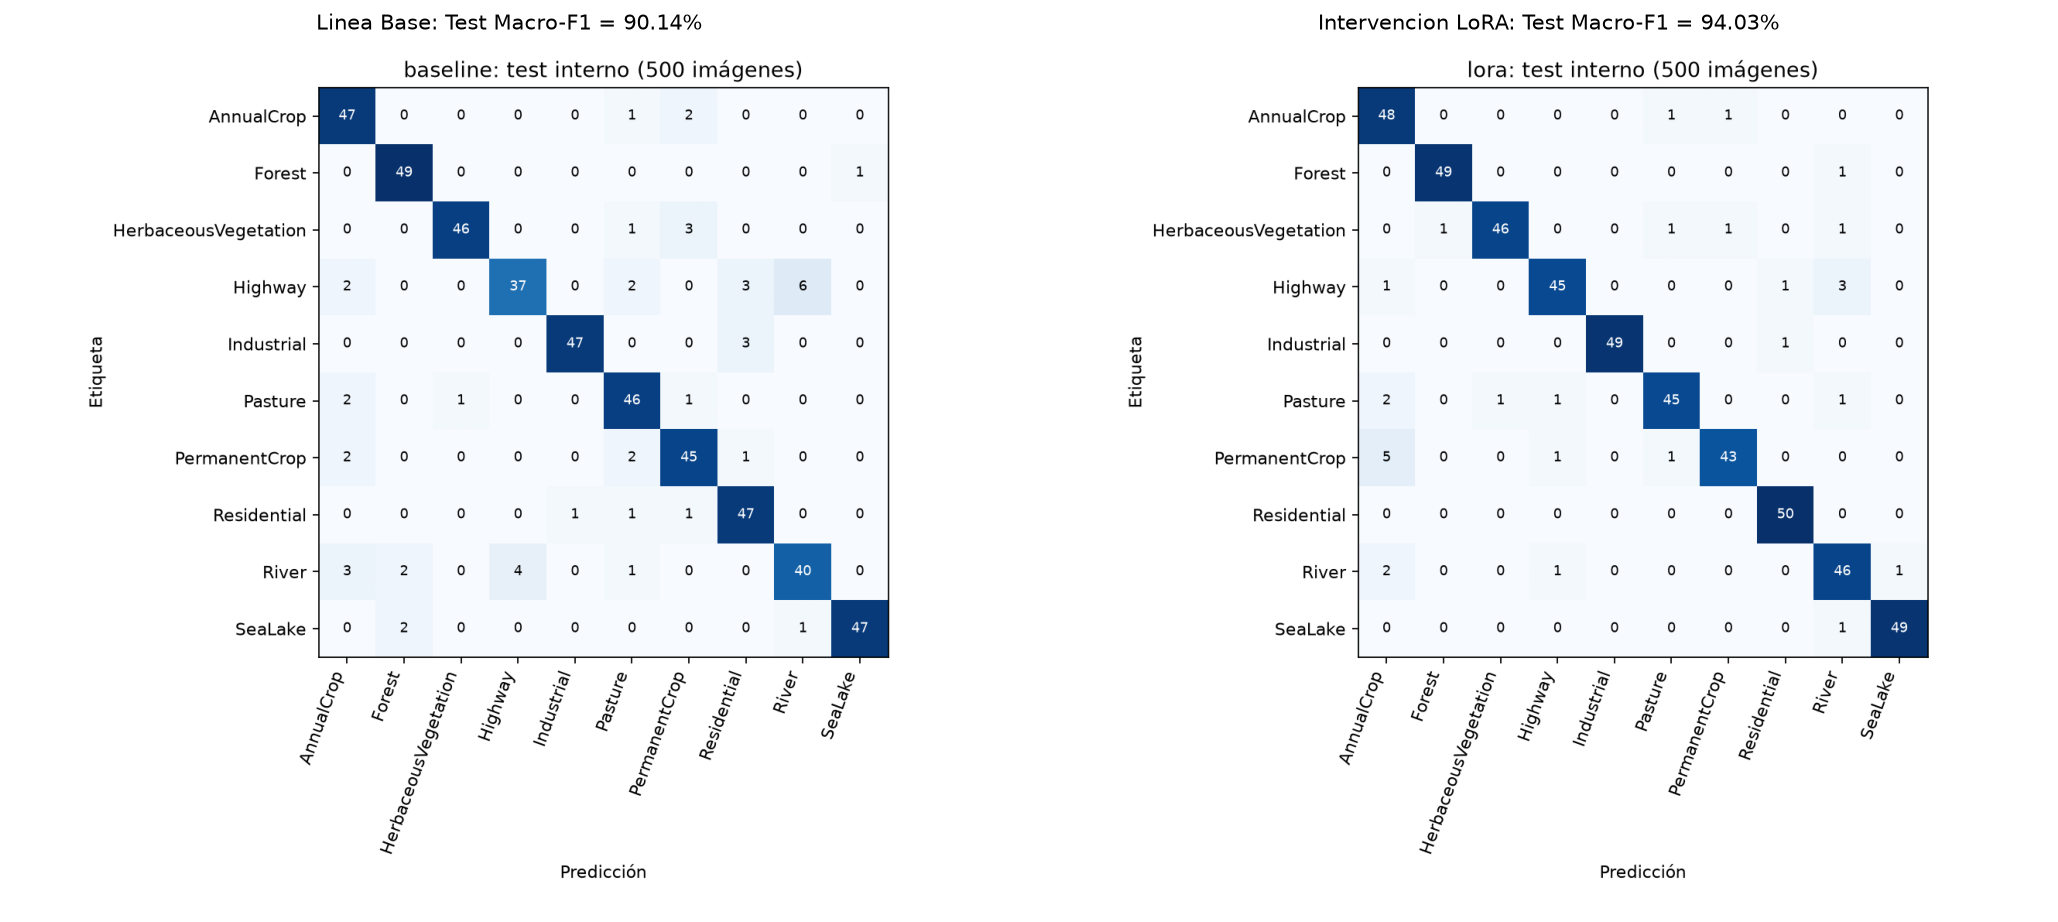

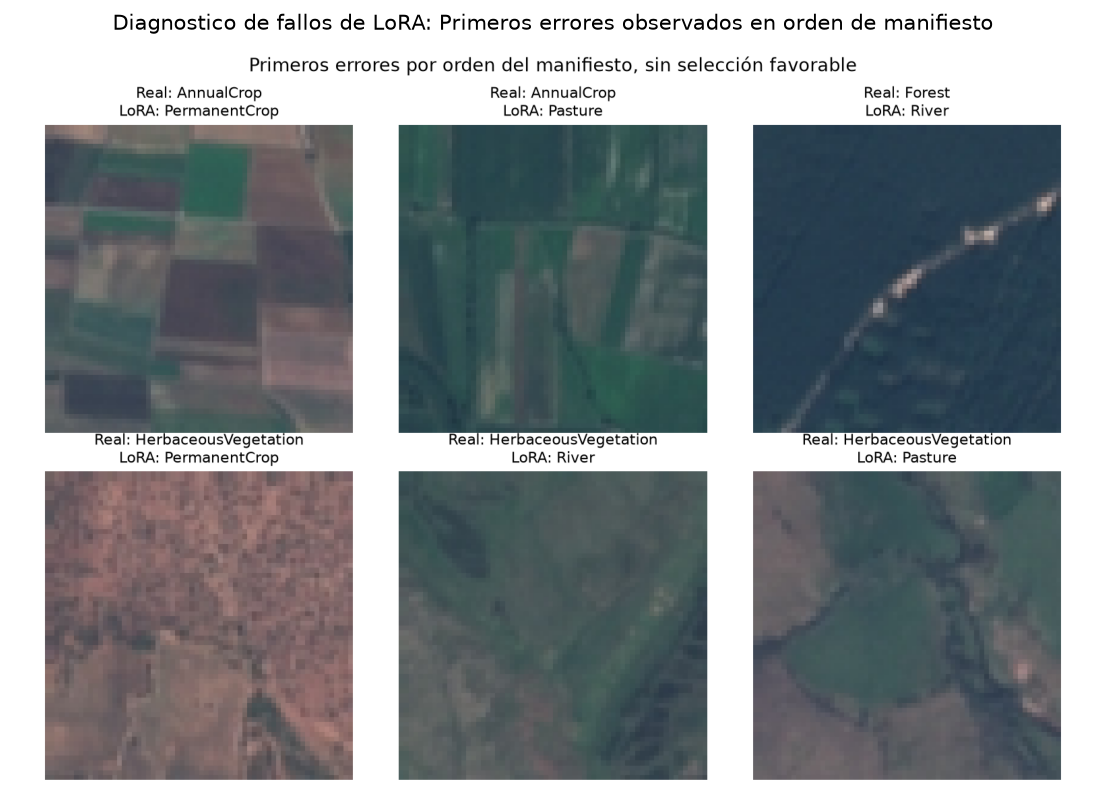

In [7]:
# Despliegue de matrices de confusion comparativas y ejemplos de fallo
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
axs[0].imshow(Image.open(FIG / "confusion_baseline.png"))
axs[0].axis("off")
axs[0].set_title("Linea Base: Test Macro-F1 = 90.14%", fontsize=11)

axs[1].imshow(Image.open(FIG / "confusion_lora.png"))
axs[1].axis("off")
axs[1].set_title("Intervencion LoRA: Test Macro-F1 = 94.03%", fontsize=11)
plt.tight_layout()
plt.show()

# Visualizacion de los primeros errores cometidos por LoRA
plt.figure(figsize=(11, 7))
plt.imshow(Image.open(FIG / "failure_examples.png"))
plt.axis("off")
plt.title("Diagnostico de fallos de LoRA: Primeros errores observados en orden de manifiesto", fontsize=11)
plt.show()


---
## 8. Contraste de la Hipotesis a Priori y Delimitaciones

### Contraste Riguroso con el Cuaderno de Decisiones (`DECISION_LOG.md`)
1. **Confirmacion de la hipotesis:** La adaptacion de bajo rango en las proyecciones de atencion $Q$ y $V$ de las dos ultimas capas produjo un incremento significativo de **+3.89 puntos porcentuales en Macro-F1 de test** (alcanzando el **94.03%** frente al 90.14% de la linea base).
2. **Eficiencia extrema de parametros:** La ganancia de rendimiento se obtuvo modificando solo **24,576 parametros adaptativos** (un incremento del **0.111%** en parametros totales respecto al modelo original).
3. **Mantenimiento de la invarianza de despliegue:** La latencia hacia adelante de la red completa en CPU aumento unicamente en **6.29 ms** (de 97.29 ms a 103.58 ms), haciendo que el modelo adaptado sea perfectamente viable para despliegue en dispositivos con restricciones computacionales.
4. **Verificacion matematica de inicializacion y congelamiento:**
   - Error de equivalencia inicial en $t=0$: **0.00** exacto.
   - Hash SHA-256 de los pesos congelados: inmutable antes y despues del entrenamiento.
   - Gradientes en el paso inicial: nulos en $W_a$ y activos en $W_b$, validando la formulacion canonica de Edward Hu et al. (2021).

### Delimitaciones y Honestidad Academica
- **Ausencia de division geografica:** Como se documento en D03, este experimento utilizo una division aleatoria estratificada. Por tanto, no se extrapola que el modelo posea robustez frente a traslados continentales o biomas no vistos.
- **Compresion espectral:** El modelo utilizo unicamente 3 canales RGB procedentes de Sentinel-2 (interpolados a $224 \times 224$ desde $64 \times 64$). Canales clave como el borde rojo (*Red Edge*), infrarrojo cercano (*NIR*) y onda corta (*SWIR*) son esenciales para resolver ambiguedades como `Highway` vs. `River` o `HerbaceousVegetation` vs. `Pasture`.

---
## 9. Hoja de Ruta hacia el Entregable 3 (Fase C)
1. **Recuperacion de Coordenadas Geograficas:** Integrar el indice espacial formal de EuroSAT para realizar validacion cruzada espacial (*Spatial Cross-Validation*) o evaluar contra dominios geograficos disjuntos.
2. **Ablacion de Hiperparametros de LoRA:** Evaluar el impacto de variar el rango $r \in \{4, 8, 16\}$ y explorar la adaptacion de la matriz de Clave ($K$) y las proyecciones SwiGLU.
3. **Aumentos de Datos para Teledeteccion:** Introducir rotaciones de multiplos de 90° e inversiones especulares cenitalmente invariantes en el ciclo de entrenamiento.
